# Sleep by hour — a step-by-step walkthrough

This notebook turns a folder of SPINDLE-scored CSVs into a **sleep-by-hour table**:
for each animal, each sleep state (wake / NREM / REM) and each 2-hour clock bin, how much
of the time was spent in that state, how many bouts there were, and how long a bout lasted.

It does **not** use the pipeline's sleep export or the `ebb` library. Every number is computed
here, in small functions, with a toy example before each real calculation. The last section
checks the result against the library as a sanity test.

**The steps**

1. Read each animal's state per epoch from its CSV
2. Upsample from one state per 4 s epoch to one state per second
3. Rotate the recording so it starts at 6 AM
4. Cut into 2-hour bins and score each bin (fraction of time, bouts, bout length)
5. Repeat for every animal
6. Fold the bins onto a 24-hour day and average across days

**Inputs:** a folder of SPINDLE CSVs (one per animal) and a `start_times.csv` giving the
clock time each recording began.

In [3]:
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 0. Settings

Everything you might change lives in this one cell.

- `SPINDLE_DIR` – the folder holding every animal's SPINDLE CSV.
- `START_TIMES_CSV` – recording start times (explained in section 1).
- `EPOCH_SEC` – SPINDLE scores one state per 4-second epoch.
- `BIN_HOURS` – width of each bin.
- `BEGIN_HR` – the clock hour that bin 0 should start at (6 = 6 AM, i.e. lights-on).

In [4]:
DATA_DIR = Path("/Users/leahmcintyre/Data/nri/Stxbp1_characterization")
SPINDLE_DIR = DATA_DIR / "spindle_outputs" / "LFC_RSC"
START_TIMES_CSV = DATA_DIR / "start_times.csv"

EPOCH_SEC = 4
BIN_HOURS = 2
BEGIN_HR = 6

STATES = ["w", "n", "r"]
STATE_NAMES = {"w": "Wake", "n": "NREM", "r": "REM"}

## 1. Animal IDs and recording start times

**Animal ID.** Each CSV name starts with the animal ID, followed by an underscore:
`Mice-1248_KO_16_54_..._labels.csv` belongs to `Mice-1248`. The ID is everything before the
first `_`.

**Start times.** A CSV is just a list of states; it doesn't say *when* the recording began.
We need that to know which epochs fall at 6 AM. `start_times.csv` has two columns,
`animal_id` and `start_datetime`, one row per animal:

```
animal_id,start_datetime
Mice-1248,2017-08-11 17:56:19
```

(It was made once by reading the start time out of each preprocessed EDF's header. Any
spreadsheet export with those two columns works.)

In [5]:
def animal_id_from_path(path: Path) -> str:
    return path.name.split("_")[0]


csv_paths = sorted(SPINDLE_DIR.glob("*.csv"))
ids = [animal_id_from_path(p) for p in csv_paths]
assert len(ids) == len(set(ids)), "two CSVs for the same animal in this folder"

start_times = pd.read_csv(START_TIMES_CSV, parse_dates=["start_datetime"])
start_by_animal = dict(zip(start_times["animal_id"], start_times["start_datetime"]))

missing = [a for a in ids if a not in start_by_animal]
assert not missing, f"no start time for: {missing}"
print(f"{len(csv_paths)} CSVs, all with start times")
start_times.head()

24 CSVs, all with start times


,animal_id,start_datetime
0,Mice-1248,2017-08-11 17:56:19
1,Mice-1251,2017-08-11 17:56:16
2,Mice-1253,2017-08-11 17:56:21
3,Mice-1254,2017-08-11 17:56:13
4,Mice-1279,2017-09-01 17:23:57


## 2. Read one animal's states

We'll work through one animal in detail, then loop over everyone.

SPINDLE's CSV has one row per 4-second epoch. The state we want is a single letter
(`w` wake, `n` NREM, `r` REM). Older SPINDLE outputs keep this in a column called
`rawstate` (their `state` column can hold artifact codes like `1`); newer outputs keep it
in `state`. So: use `rawstate` if it exists, otherwise `state`.

In [6]:
def load_states(path: Path) -> np.ndarray:
    header = pd.read_csv(path, nrows=0).columns
    col = "rawstate" if "rawstate" in header else "state"
    states = pd.read_csv(path, usecols=[col])[col].to_numpy()
    assert set(states) <= set(STATES), f"unexpected state values: {set(states) - set(STATES)}"
    return states


example_path = csv_paths[0]
example_id = animal_id_from_path(example_path)
epoch_states = load_states(example_path)

print(example_id)
print("epochs:", len(epoch_states))
print("hours :", len(epoch_states) * EPOCH_SEC / 3600)
print("first 20 epochs:", "".join(epoch_states[:20]))

Mice-1248
epochs: 64800
hours : 72.0
first 20 epochs: wwwwwwwwwwwwnnnnwwwn


Quick look at the raw hypnogram (state over time), measured from the start of the recording.

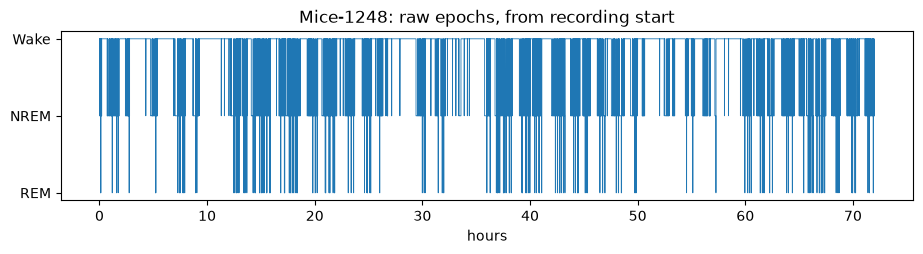

In [7]:
def plot_hypnogram(states, step_sec, t0_hr=0, title=""):
    level = {"r": 0, "n": 1, "w": 2}
    y = np.array([level[s] for s in states])
    t = t0_hr + np.arange(len(y)) * step_sec / 3600
    fig, ax = plt.subplots(figsize=(11, 2.2))
    ax.step(t, y, where="post", lw=0.6)
    ax.set_yticks([0, 1, 2], ["REM", "NREM", "Wake"])
    ax.set_xlabel("hours")
    ax.set_title(title)
    return ax


plot_hypnogram(epoch_states, EPOCH_SEC, title=f"{example_id}: raw epochs, from recording start");

## 3. Upsample to one state per second

Every later step is easier if one array position equals one second. Each epoch is 4 s long,
so we repeat each state 4 times.

Toy example: three epochs `w n r` become twelve seconds.

In [8]:
toy = np.array(["w", "n", "r"])
print(np.repeat(toy, EPOCH_SEC))

['w' 'w' 'w' 'w' 'n' 'n' 'n' 'n' 'r' 'r' 'r' 'r']


In [9]:
def upsample(epoch_states: np.ndarray, epoch_sec: int = EPOCH_SEC) -> np.ndarray:
    return np.repeat(epoch_states, epoch_sec)


sec_states = upsample(epoch_states)
print(f"{len(epoch_states)} epochs -> {len(sec_states)} seconds")

64800 epochs -> 259200 seconds


## 4. Rotate so the recording starts at 6 AM

Animals don't all start recording at the same time of day, so their raw bin 0 means different
clock times. To compare animals, we shift each recording so that **its first 6 AM is
position 0**, and the stretch that came *before* that first 6 AM moves to the end.

1. Find how many seconds pass between the recording start and the next 6:00.
2. Drop that many seconds from the front of the array and tack them onto the back.

Example: a recording starting at 17:56:19 reaches the next 6 AM after 12 h 3 min 41 s
= 43,421 s.

In [10]:
def seconds_until_next(start: datetime, hour: int) -> int:
    """Seconds from `start` forward to the next `hour`:00 (today's if not yet passed)."""
    target = start.replace(hour=hour, minute=0, second=0, microsecond=0)
    if start > target:
        target += timedelta(days=1)
    return int((target - start).total_seconds())


example_start = start_by_animal[example_id]
offset = seconds_until_next(example_start, BEGIN_HR)
print("recording starts:", example_start)
print("seconds until next 6 AM:", offset, f"({offset / 3600:.2f} h)")

recording starts: 2017-08-11 17:56:19
seconds until next 6 AM: 43421 (12.06 h)


In [11]:
def rotate(sec_states: np.ndarray, offset: int) -> np.ndarray:
    return np.concatenate([sec_states[offset:], sec_states[:offset]])


rotated = rotate(sec_states, offset)

# the same thing, spelled out: rotated[0] is the state at exactly 6 AM
assert rotated[0] == sec_states[offset]
assert len(rotated) == len(sec_states)

Two things to keep in mind:

- A recording shorter than `offset` never reaches 6 AM, so it can't be rotated. Such animals
  are skipped (with a printed warning) below.
- Start times here are naive clock times with no timezone, so every day is treated as 24 h.
  A recording that spans a daylight-saving change is off by an hour after the change.

## 5. Score a bin: fraction of time and bouts

Cut the rotated array into consecutive 2-hour pieces (7,200 seconds each). For every state in
a piece we compute three numbers.

- **`frac_time`** – seconds in the state ÷ seconds in the bin.
- **`n_bouts`** – number of separate runs of that state. A *bout* is an unbroken stretch.
- **`mean_bout_sec`** – the average length of those runs in seconds (`NaN` if there were none).

The bout counting is the only tricky part, so here it is on a toy bin. Take a mask that is
`True` wherever the state is present:

In [12]:
mask = np.array([0, 1, 1, 0, 1, 0, 0, 1, 1, 1], dtype=bool)

change = np.diff(mask.astype(int))    # +1 where a run starts, -1 where it ends
starts = np.where(change == 1)[0] + 1   # the run begins on the sample *after* the change
ends = np.where(change == -1)[0] + 1    # one past the last sample of the run

print("diff  :", change)
print("starts:", starts, "  ends:", ends)

diff  : [ 1  0 -1  1 -1  0  1  0  0]
starts: [1 4 7]   ends: [3 5]


The last run (positions 7–9) has a start but no end, because the bin ends first. Likewise a
run that is already going at position 0 has an end but no start. We patch both edges:

In [13]:
def bouts(mask: np.ndarray):
    """Return (number of bouts, mean bout length in samples) for a boolean mask."""
    change = np.diff(mask.astype(int))
    starts = np.where(change == 1)[0] + 1
    ends = np.where(change == -1)[0] + 1
    if mask[0]:
        starts = np.r_[0, starts]
    if mask[-1]:
        ends = np.r_[ends, len(mask)]
    if len(starts) == 0:
        return 0, np.nan
    return len(starts), (ends - starts).mean()


n, mean_len = bouts(mask)
print(f"{n} bouts, mean length {mean_len:.2f} samples")   # runs of length 2, 1, 3

3 bouts, mean length 2.00 samples


Now one real bin by hand: the first 2 hours of the rotated example animal (so 6–8 AM).

In [14]:
bin_len = BIN_HOURS * 3600
first_bin = rotated[:bin_len]

rows = []
for state in STATES:
    m = first_bin == state
    n_bouts, mean_sec = bouts(m)
    rows.append({"state": state, "frac_time": m.sum() / len(first_bin),
                 "n_bouts": n_bouts, "mean_bout_sec": mean_sec})
pd.DataFrame(rows)

,state,frac_time,n_bouts,mean_bout_sec
0,w,0.386667,26,107.076923
1,n,0.537778,25,154.880000
2,r,0.075556,11,49.454545


Fractions across the three states should add to 1.

In [15]:
assert abs(sum(r["frac_time"] for r in rows) - 1) < 1e-9

## 6. All bins for one animal

Loop over every bin. The last bin is usually shorter than 2 hours (the recording rarely
divides evenly), so its fractions are taken over *its own* length.

`bin_start_hr` is the clock hour the bin begins: bin 0 starts at `BEGIN_HR`, and it grows by
`BIN_HOURS` each bin, *without* wrapping at 24. A 72 h recording therefore has bin starts
6, 8, … 28, 30, … so day 2 and day 3 stay distinct for now.

In [16]:
def bin_metrics(rotated: np.ndarray, animal: str) -> pd.DataFrame:
    bin_len = BIN_HOURS * 3600
    rows = []
    for bin_idx, start in enumerate(range(0, len(rotated), bin_len)):
        chunk = rotated[start:start + bin_len]
        for state in STATES:
            m = chunk == state
            n_bouts, mean_sec = bouts(m)
            rows.append({
                "mouse_id": animal,
                "bin_idx": bin_idx,
                "bin_start_hr": BEGIN_HR + bin_idx * BIN_HOURS,
                "state": state,
                "frac_time": m.sum() / len(chunk),
                "n_bouts": n_bouts,
                "mean_bout_sec": mean_sec,
            })
    return pd.DataFrame(rows)


example_bins = bin_metrics(rotated, example_id)
example_bins.head(6)

,mouse_id,bin_idx,bin_start_hr,state,frac_time,n_bouts,mean_bout_sec
0,Mice-1248,0,6,w,0.386667,26,107.076923
1,Mice-1248,0,6,n,0.537778,25,154.880000
2,Mice-1248,0,6,r,0.075556,11,49.454545
3,Mice-1248,1,8,w,0.196111,39,36.205128
4,Mice-1248,1,8,n,0.688889,38,130.526316
5,Mice-1248,1,8,r,0.115000,15,55.200000


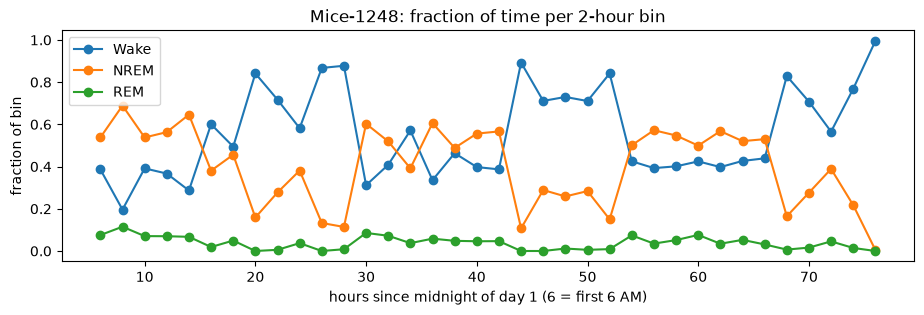

In [17]:
fig, ax = plt.subplots(figsize=(11, 3))
for state in STATES:
    sub = example_bins[example_bins["state"] == state]
    ax.plot(sub["bin_start_hr"], sub["frac_time"], marker="o", label=STATE_NAMES[state])
ax.set_xlabel("hours since midnight of day 1 (6 = first 6 AM)")
ax.set_ylabel("fraction of bin")
ax.set_title(f"{example_id}: fraction of time per 2-hour bin")
ax.legend();

## 7. Every animal

Now we wrap sections 2–6 into one function and run it over all the CSVs. Animals whose
recording is too short to reach 6 AM are skipped with a message.

In [18]:
def sleep_bins_for_animal(path: Path):
    animal = animal_id_from_path(path)
    sec_states = upsample(load_states(path))
    offset = seconds_until_next(start_by_animal[animal], BEGIN_HR)
    if offset >= len(sec_states):
        print(f"skipping {animal}: recording ends before it reaches {BEGIN_HR}:00")
        return None
    return bin_metrics(rotate(sec_states, offset), animal)


per_animal = [sleep_bins_for_animal(p) for p in csv_paths]
sleep_bins = pd.concat([d for d in per_animal if d is not None], ignore_index=True)

print(sleep_bins["mouse_id"].nunique(), "animals,", len(sleep_bins), "rows")
sleep_bins.head()

24 animals, 2592 rows


,mouse_id,bin_idx,bin_start_hr,state,frac_time,n_bouts,mean_bout_sec
0,Mice-1248,0,6,w,0.386667,26,107.076923
1,Mice-1248,0,6,n,0.537778,25,154.880000
2,Mice-1248,0,6,r,0.075556,11,49.454545
3,Mice-1248,1,8,w,0.196111,39,36.205128
4,Mice-1248,1,8,n,0.688889,38,130.526316


## 8. Fold onto a 24-hour day and average across days

`sleep_bins` has one row per animal × state × bin, with bins running across all days of the
recording. To get a typical day, we map each bin onto its clock hour with `% 24` (hour 30 is
6 AM again), then average each metric over the days that share that hour.

`n_days` records how many bins went into each average. It's lower than the number of days
for any hour that the recording only partly covers. Note that every bin counts equally, even a
short final one.

In [19]:
METRICS = ["frac_time", "n_bouts", "mean_bout_sec"]

sleep_bins["hour_of_day"] = (sleep_bins["bin_start_hr"] % 24).astype(int)

grouped = sleep_bins.groupby(["mouse_id", "state", "hour_of_day"], as_index=False)
sleep_bins_avg = grouped[METRICS].mean()
sleep_bins_avg["n_days"] = grouped.size()["size"]
sleep_bins_avg = sleep_bins_avg.sort_values(["mouse_id", "state", "hour_of_day"], ignore_index=True)

sleep_bins_avg.head(12)

,mouse_id,state,hour_of_day,frac_time,n_bouts,mean_bout_sec,n_days
0,Mice-1248,n,0,0.342824,17.333333,141.572682,3
1,Mice-1248,n,2,0.211250,13.333333,113.324786,3
2,Mice-1248,n,4,0.089676,6.000000,97.208333,3
3,Mice-1248,n,6,0.547222,28.000000,142.282353,3
4,Mice-1248,n,8,0.593472,31.000000,139.986550,3
5,Mice-1248,n,10,0.492315,30.333333,116.767384,3
6,Mice-1248,n,12,0.556157,29.666667,136.094910,3
7,Mice-1248,n,14,0.567454,39.666667,108.616092,3
8,Mice-1248,n,16,0.485787,28.000000,126.654834,3
9,Mice-1248,n,18,0.517546,30.666667,123.279426,3


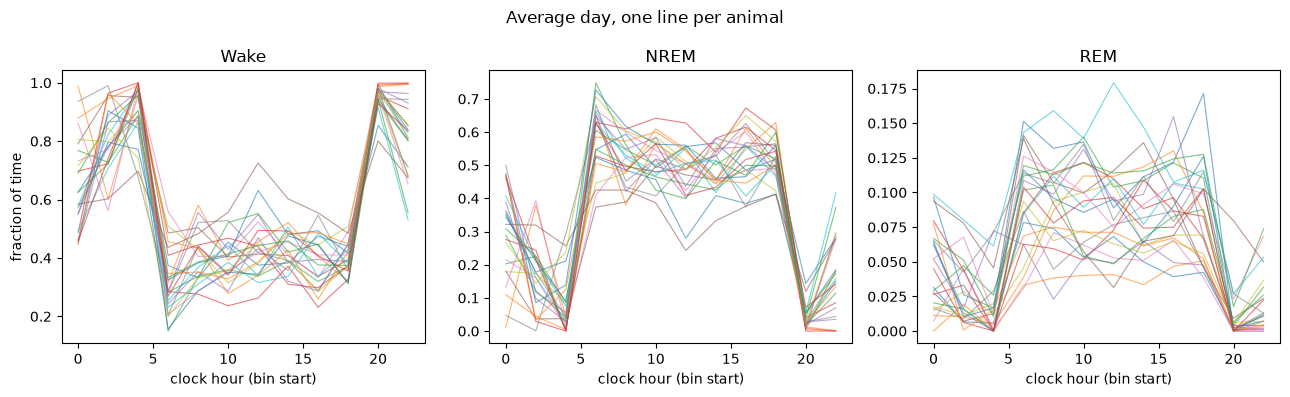

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True)
for ax, state in zip(axes, STATES):
    sub = sleep_bins_avg[sleep_bins_avg["state"] == state]
    for animal, d in sub.groupby("mouse_id"):
        ax.plot(d["hour_of_day"], d["frac_time"], lw=0.8, alpha=0.6)
    ax.set_title(STATE_NAMES[state])
    ax.set_xlabel("clock hour (bin start)")
axes[0].set_ylabel("fraction of time")
fig.suptitle("Average day, one line per animal");
fig.tight_layout()

## 9. Check against the library

This section is the only place `ebb` is used. It runs the pipeline's own calculation on the
same CSVs and compares. Skip it if you don't have `ebb` installed.

The library takes start times from the preprocessed EDFs in `standard/`, so the start-times
file (made from those same EDFs) should give identical numbers.

In [26]:
from ebb.process.sleep_compute import compute_sleep_bins_df_offset

lib = compute_sleep_bins_df_offset(SPINDLE_DIR, DATA_DIR / "standard", bin_hours=BIN_HOURS, begin_hr=BEGIN_HR)

key = ["mouse_id", "bin_idx", "state"]
merged = sleep_bins.merge(lib, on=key, suffixes=("", "_lib"), how="inner")
print(f"{len(merged)} of {len(sleep_bins)} rows matched on {key}")

for col in METRICS:
    # equal_nan: mean_bout_sec is NaN when a state has no bouts in the bin
    ok = np.allclose(merged[col], merged[f"{col}_lib"], equal_nan=True)
    print(f"{col:15s} matches library: {ok}")

2592 of 2592 rows matched on ['mouse_id', 'bin_idx', 'state']
frac_time       matches library: True
n_bouts         matches library: True
mean_bout_sec   matches library: True


## Next

`sleep_bins_avg` has the columns the Prism notebook expects (`mouse_id`, `state`,
`hour_of_day`, the three metrics and `n_days`). Continuing from here: assign animals to
groups, convert to ZT, and write the Prism workbook as in `sleep_by_hour_to_prism.ipynb`.